# Darija Project — Pipeline de Nettoyage Complet

**Projet :** Classification automatique de textes en Darija marocaine  
**Conforme à :** Section 7.1 / 7.2 / 7.3 / Section 14 du cahier des charges  

---

## Structure du notebook

| Étape | Description | Section CDC |
|-------|-------------|-------------|
| 0 | Installation & imports | — |
| 1 | Chargement des données brutes | — |
| 2 | Nettoyage de base (URLs, spam, répétitions) | 7.2 |
| 3 | Filtre contenu non-linguistique (emojis purs) | 14 |
| 4 | Classification Darija vs MSA | 14 |
| 5 | Déduplication (hash exact + Jaccard) | Qualité |
| 6 | Normalisation légère (alef + diacritiques) | 7.2 |
| 7 | Annotation meta-features | 7.3 |
| 8 | Analyse exploratoire (EDA) | 7.3 |
| 9 | Export final | — |

---
## Étape 0 — Installation & Imports

In [1]:
# Installation des dépendances
!pip install pandas emoji langdetect tqdm matplotlib seaborn --quiet


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import re
import json
import hashlib
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

tqdm.pandas()

# Optionnels
try:
    import emoji as emoji_lib
    EMOJI_OK = True
    print("✓ emoji installé")
except ImportError:
    EMOJI_OK = False
    print("⚠ emoji non installé — fallback regex activé")

try:
    from langdetect import detect, LangDetectException
    LANGDETECT_OK = True
    print("✓ langdetect installé")
except ImportError:
    LANGDETECT_OK = False
    print("⚠ langdetect non installé — fallback scores activé")

print("\n✓ Tous les imports chargés")

✓ emoji installé
✓ langdetect installé

✓ Tous les imports chargés


In [3]:
# ── Chemins (adapter si nécessaire)
INPUT_PATH  = Path("../../01_extraction/scraper_hajar/data/merged/dataset_merged.csv")   # sortie de l'étape 1 (merge_partners.py)
OUTPUT_DIR  = Path("data/processed")
REPORT_DIR  = Path("data/reports")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Input  : {INPUT_PATH}")
print(f"Output : {OUTPUT_DIR}")
print(f"Report : {REPORT_DIR}")

Input  : dataset_merged.csv
Output : data\processed
Report : data\reports


---
## Étape 1 — Chargement des données brutes

In [4]:
# Chargement CSV ou JSON selon ce qui existe
if INPUT_PATH.exists():
    df = pd.read_csv(INPUT_PATH, encoding="utf-8-sig", dtype=str)
    print(f"✓ CSV chargé : {INPUT_PATH}")
else:
    json_path = INPUT_PATH.with_suffix(".json")
    if json_path.exists():
        df = pd.DataFrame(json.loads(json_path.read_text(encoding="utf-8")))
        print(f"✓ JSON chargé : {json_path}")
    else:
        raise FileNotFoundError(f"Fichier introuvable : {INPUT_PATH}")

# Normaliser la colonne text
df["text"] = df["text"].fillna("").astype(str)

N0 = len(df)
print(f"\n{'='*50}")
print(f"Textes chargés    : {N0:,}")
print(f"Colonnes          : {list(df.columns)}")
print(f"{'='*50}")

✓ CSV chargé : dataset_merged.csv

Textes chargés    : 175,857
Colonnes          : ['id', 'text', 'source_type', 'domain', 'channel_name', 'published_at', 'label', 'language']


In [5]:
# Aperçu des données brutes
df.head(5)

,id,text,source_type,domain,channel_name,published_at,label,language
0,darija_000000,شكرا بزاف بارك الله فيك شرح ممتاز❤,youtube_comment,business,Abdo Nobil,1757462400,business,darija
1,darija_000001,Tooop tbarkallah 3lik 😊,youtube_comment,business,Abdo Nobil,1741564800,business,darija
2,darija_000002,جزاك الله خيرا,youtube_comment,business,Abdo Nobil,1741564800,business,darija
3,darija_000003,تبارك الله عليك \nالله جزيك عنا خيرا,youtube_comment,business,Abdo Nobil,1741564800,business,darija
4,darija_000004,3afak KML m3ana xrh dyalk zwin tbrklah LAH yrh...,youtube_comment,business,Abdo Nobil,1741564800,business,darija


In [6]:
# Statistiques de base
print("Distribution par source :")
print(df["source_type"].value_counts())
print("\nDistribution par catégorie :")
print(df["domain"].value_counts())

Distribution par source :
source_type
youtube_comment    123717
youtube comment     52140
Name: count, dtype: int64

Distribution par catégorie :
domain
food             39019
entertainment    35433
politics         32641
business         19141
religion         16438
medical          16299
sports           12452
miscill           4434
Name: count, dtype: int64


---
## Étape 2 — Nettoyage de base

> **Section 7.2** : *nettoyage léger (URLs, emojis, spam) — éviter le sur-nettoyage*

**Quoi :** URLs, @mentions, spam patterns, caractères invisibles, répétitions abusives  
**Pourquoi :** Ces éléments ne portent aucune information thématique. Ils biaiseraient les features du classifieur.  
**Ce qu'on ne touche PAS :** orthographe Darija, code-switching, Arabizi, fautes volontaires

In [7]:
# ── Patterns de spam YouTube
_SPAM_RE = re.compile(
    r"(?i)(sub\s*4\s*sub"
    r"|sub\s*for\s*sub"
    r"|check\s*out\s*my\s*channel"
    r"|visit\s*my\s*profile"
    r"|first\s*!+"
    r"|https?://\S+"
    r"|www\.\S+)"
)

def clean_basic(text: str) -> str:
    """
    Nettoyage de surface UNIQUEMENT.
    Préserve : orthographe Darija, code-switching, Arabizi, style oral.
    """
    if not isinstance(text, str):
        return ""
    # URLs et mentions
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"#(\w+)", r"\1", text)          # retire #, garde le mot
    # Caractères de contrôle et zero-width
    text = re.sub(r"[\x00-\x08\x0b-\x1f\x7f]", "", text)
    text = re.sub(r"[\u200b-\u200f\u202a-\u202e\ufeff]", "", text)
    # Répétitions > 4 → réduit à 2 (garde le style : bzzaf mais pas bzzzzzzaf)
    text = re.sub(r"(.)\1{4,}", r"\1\1", text)
    # Espaces multiples
    text = re.sub(r" {2,}", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


def is_spam(text: str) -> bool:
    """True si le texte est clairement du spam."""
    t = text.strip()
    if len(t) < 5:
        return True
    # Ratio alphabétique < 20% → probablement du bruit
    if sum(1 for c in t if c.isalpha()) / max(len(t), 1) < 0.20:
        return True
    if _SPAM_RE.search(t):
        return True
    return False


print("Fonctions de nettoyage définies.")

# Test rapide
tests = [
    "https://youtu.be/xyz bzzaf zwina",
    "bzzzzzzaf had lfilm",
    "@DrMouad sub4sub",
    "3la khatirak khoya",
]
for t in tests:
    print(f"  AVANT : {t!r}")
    print(f"  APRÈS : {clean_basic(t)!r}")
    print()

Fonctions de nettoyage définies.
  AVANT : 'https://youtu.be/xyz bzzaf zwina'
  APRÈS : 'bzzaf zwina'

  AVANT : 'bzzzzzzaf had lfilm'
  APRÈS : 'bzzaf had lfilm'

  AVANT : '@DrMouad sub4sub'
  APRÈS : 'sub4sub'

  AVANT : '3la khatirak khoya'
  APRÈS : '3la khatirak khoya'



In [8]:
# Application sur le dataset complet
df["text"] = df["text"].progress_apply(clean_basic)

# Suppression du spam
mask_spam = df["text"].apply(is_spam)
n_spam = mask_spam.sum()
df = df[~mask_spam].copy().reset_index(drop=True)

N1 = len(df)
print(f"Textes spam supprimés : {n_spam:,}")
print(f"Textes restants       : {N1:,} ({N1/N0*100:.1f}% conservés)")

  0%|          | 0/175857 [00:00<?, ?it/s]

Textes spam supprimés : 3,717
Textes restants       : 172,140 (97.9% conservés)


---
## Étape 3 — Filtre contenu non-linguistique

> **Section 14** : *commentaires uniquement des emojis → exclure*

**Quoi :** Textes composés uniquement d'emojis ou de ponctuation sans lettre alphabétique  
**Pourquoi :** Impossible à classifier thématiquement — aucun classifieur ne peut décider de la catégorie d'un texte sans mot

In [9]:
# Regex emojis (fallback si librairie emoji absente)
_EMOJI_RE = re.compile(
    "["
    "\U0001F600-\U0001F64F"
    "\U0001F300-\U0001F5FF"
    "\U0001F680-\U0001F9FF"
    "\U00002600-\U000027BF"
    "\U0001F1E0-\U0001F1FF"
    "\U00002702-\U000027B0"
    "]+",
    flags=re.UNICODE,
)

def strip_emojis(text: str) -> str:
    if EMOJI_OK:
        return emoji_lib.replace_emoji(text, replace=" ").strip()
    return _EMOJI_RE.sub(" ", text).strip()


def is_only_emojis(text: str) -> bool:
    """
    True si après suppression des emojis il reste < 3 chars alphabétiques.
    Ex: '👏👏👏' → True | 'bzzaf 👍' → False
    """
    stripped = strip_emojis(text)
    alpha = re.sub(r"[^\w]", "", stripped)
    return len(alpha) < 3


# Test
tests_emoji = ["👏👏👏👏", "❤️❤️", "bzzaf zwina 👍", "مزيان 🔥", "فنان"]
for t in tests_emoji:
    res = is_only_emojis(t)
    status = "❌ exclu" if res else "✓ gardé"
    print(f"  {status} : {t!r}")

  ❌ exclu : '👏👏👏👏'
  ❌ exclu : '❤️❤️'
  ✓ gardé : 'bzzaf zwina 👍'
  ✓ gardé : 'مزيان 🔥'
  ✓ gardé : 'فنان'


In [10]:
# Application
mask_emoji = df["text"].apply(is_only_emojis)
n_emoji = mask_emoji.sum()
df = df[~mask_emoji].copy().reset_index(drop=True)

N2 = len(df)
print(f"Textes emoji-only supprimés : {n_emoji:,}")
print(f"Textes restants             : {N2:,} ({N2/N0*100:.1f}% conservés)")

Textes emoji-only supprimés : 73
Textes restants             : 172,067 (97.8% conservés)


---
## Étape 4 — Classification Darija vs MSA

> **Section 14** : Garder Darija (latin / arabe / mixte), exclure MSA formel

**Quoi :** 3 scores calculés sur chaque texte → classification en 5 types  
**Pourquoi :** Le MSA formel (style journalistique, institutionnel) a un vocabulaire et une syntaxe radicalement différents du Darija. L'inclure biaise les features du classifieur.

**Types :**
- `darija_latin` → ✅ garder
- `darija_arabic` → ✅ garder  
- `darija_mixed` → ✅ garder
- `msa` → ❌ exclure
- `other` → ❌ exclure

In [41]:
# ══════════════════════════════════════════════════════════════════════
# Étape 4 — Détecteur Darija robuste (5 couches)
# Lexique ~900 mots + heuristiques structurelles + morphologie
# + Arabizi + marqueurs MSA syntaxiques
# ══════════════════════════════════════════════════════════════════════
import importlib.util

detector_path = Path("darija_detector.py")
assert detector_path.exists(), (
    "⚠ Placez darija_detector.py dans le même dossier que ce notebook"
)
spec = importlib.util.spec_from_file_location("dd", detector_path)
mod  = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)

analyze       = mod.analyze
classify      = mod.classify
should_keep   = mod.should_keep
DARIJA_LATIN  = mod.DARIJA_LATIN
DARIJA_ARABIC = mod.DARIJA_ARABIC
MSA_MARKERS   = mod.MSA_MARKERS

print("✓ darija_detector chargé")
print(f"  Lexique Darija latin  : {len(DARIJA_LATIN):,} mots")
print(f"  Lexique Darija arabe  : {len(DARIJA_ARABIC):,} mots")
print(f"  Marqueurs MSA         : {len(MSA_MARKERS):,} mots")
print()
print("  Couches : [1] Lexique  [2] Structures  [3] Arabizi  [4] Morpho  [5] MSA/FR")

✓ darija_detector chargé
  Lexique Darija latin  : 526 mots
  Lexique Darija arabe  : 430 mots
  Marqueurs MSA         : 151 mots

  Couches : [1] Lexique  [2] Structures  [3] Arabizi  [4] Morpho  [5] MSA/FR


In [42]:
# ── Validation Section 14 avant application
from IPython.display import display

sec14 = [
    ("سلام دكتوره انا وجهي فيه حبوب بزاف رقيق وغليظ",  "✓ garder"),
    ("Mskine ta7 mn sta7",                               "✓ garder"),
    ("Hadi 7El9a zwina bzzaf",                           "✓ garder"),
    ("هادي خاسها فيديو آخر للناس اللي مكيقراوش",         "✓ garder"),
    ("ياله كنت شاد سلسلة تاعك ونشدو بها رمضان",          "✓ garder"),
    ("واش كاين chi doctor zwina ف casablanca بزاف",       "✓ garder"),
    ("يجب استقالة جميع الأحزاب السياسية في المغرب",      "✗ exclure"),
    ("وأشار المسؤول أن الحكومة اتخذت قرارات وفقاً للدستور", "✗ exclure"),
    ("c'est vraiment une très bonne vidéo merci",         "✗ exclure"),
    ("bravo excellent travail continuez comme ça",        "✗ exclure"),
    ("👏👏👏👏👏",                                         "✗ exclure"),
    ("فنان بما تحمله الكلمة",                             "✗ exclure"),
]

rows = []
for txt, expected in sec14:
    clean = strip_emojis(txt)
    if len(re.sub(r"[^\w]", "", clean)) < 3:
        dt, conf = "other", 0.0
    else:
        dt, conf = classify(txt)
    decision = "✓ garder" if dt.startswith("darija") else "✗ exclure"
    ok = "✓" if decision == expected else "✗"
    rows.append({"": ok, "texte": txt[:52], "type": dt,
                 "conf": f"{conf:.2f}", "attendu": expected})

display(pd.DataFrame(rows))
score = sum(1 for r in rows if r[""] == "✓")
print(f"\nPrécision Section 14 : {score}/{len(rows)} ({score/len(rows)*100:.0f}%)")

,,texte,type,conf,attendu
0,✓,سلام دكتوره انا وجهي فيه حبوب بزاف رقيق وغليظ,darija_arabic,0.55,✓ garder
1,✓,Mskine ta7 mn sta7,darija_latin,1.00,✓ garder
2,✓,Hadi 7El9a zwina bzzaf,darija_latin,1.00,✓ garder
3,✓,هادي خاسها فيديو آخر للناس اللي مكيقراوش,darija_arabic,0.29,✓ garder
4,✓,ياله كنت شاد سلسلة تاعك ونشدو بها رمضان,darija_arabic,0.50,✓ garder
5,✓,واش كاين chi doctor zwina ف casablanca بزاف,darija_mixed,0.75,✓ garder
6,✓,يجب استقالة جميع الأحزاب السياسية في المغرب,msa,0.96,✗ exclure
7,✓,وأشار المسؤول أن الحكومة اتخذت قرارات وفقاً لل...,msa,0.94,✗ exclure
8,✓,c'est vraiment une très bonne vidéo merci,french,0.67,✗ exclure
9,✓,bravo excellent travail continuez comme ça,french,0.80,✗ exclure



Précision Section 14 : 12/12 (100%)


Classification (peut prendre quelques minutes)...


  0%|          | 0/70018 [00:00<?, ?it/s]


Distribution des types détectés :
  ✓ darija_arabic       44,859  (64.1%)
  ✓ darija_latin        24,503  (35.0%)
  ✓ darija_mixed           467  (0.7%)
  ✗ other                   99  (0.1%)
  ✗ msa                     88  (0.1%)
  ✗ french                   2  (0.0%)


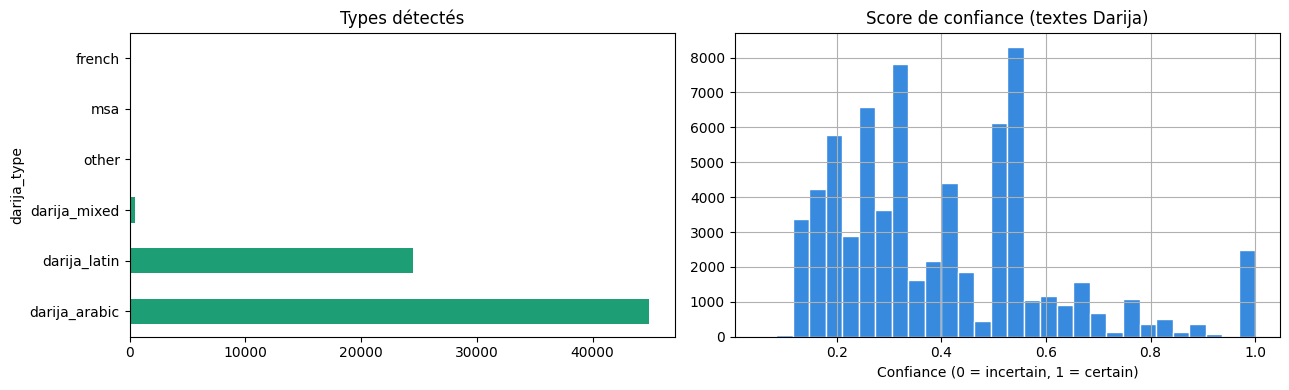

In [43]:
# ── Application sur le dataset complet
print("Classification (peut prendre quelques minutes)...")

results          = df["text"].progress_apply(classify)
df["darija_type"]    = [r[0] for r in results]
df["det_confidence"] = [round(r[1], 4) for r in results]

print("\nDistribution des types détectés :")
vc = df["darija_type"].value_counts()
for t, c in vc.items():
    icon = "✓" if t.startswith("darija") else "✗"
    print(f"  {icon} {t:<18} {c:>7,}  ({c/len(df)*100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

colors = ["#1D9E75" if t.startswith("darija") else "#E24B4A" for t in vc.index]
vc.plot.barh(ax=axes[0], color=colors)
axes[0].set_title("Types détectés")

darija_df = df[df["darija_type"].str.startswith("darija")]
if len(darija_df):
    darija_df["det_confidence"].hist(bins=30, ax=axes[1],
                                     color="#378ADD", edgecolor="white")
axes[1].set_title("Score de confiance (textes Darija)")
axes[1].set_xlabel("Confiance (0 = incertain, 1 = certain)")

plt.tight_layout()
plt.savefig(REPORT_DIR / "plot_classification.png", dpi=150, bbox_inches="tight")
plt.show()

In [44]:
# ── Filtrage : garder Darija uniquement
before = len(df)
df = df[df["darija_type"].isin(
    ["darija_latin", "darija_arabic", "darija_mixed"]
)].copy().reset_index(drop=True)

N3 = len(df)
N0 = N0 if "N0" in dir() else before  # fallback si N0 non défini

print(f"MSA / français / autres exclus : {before - N3:,}")
print(f"Textes Darija conservés        : {N3:,}  ({N3/N0*100:.1f}% du total initial)")
print()
print("Répartition finale :")
for t, c in df["darija_type"].value_counts().items():
    print(f"  {t:<22} {c:>7,}  ({c/N3*100:.1f}%)")

MSA / français / autres exclus : 189
Textes Darija conservés        : 69,829  (39.7% du total initial)

Répartition finale :
  darija_arabic           44,859  (64.2%)
  darija_latin            24,503  (35.1%)
  darija_mixed               467  (0.7%)


---
## Étape 5 — Déduplication

**Niveau 1 :** Hash MD5 exact → suppression immédiate  
**Niveau 2 :** Similarité Jaccard sur k-shingles (seuil 85%) → quasi-doublons  
**Pourquoi :** Éviter que le même texte soit vu plusieurs fois à l'entraînement, ce qui gonflerait artificiellement les métriques

In [45]:
def fingerprint(text: str) -> str:
    """Hash MD5 normalisé pour déduplication exacte."""
    normalized = re.sub(r"\s+", " ", text.lower().strip())
    return hashlib.md5(normalized.encode("utf-8")).hexdigest()


def shingles(text: str, k: int = 3) -> frozenset:
    """K-shingles de mots pour la similarité Jaccard."""
    w = text.lower().split()
    return frozenset(" ".join(w[i:i+k]) for i in range(max(len(w)-k+1, 1)))


def jaccard(a: frozenset, b: frozenset) -> float:
    if not a or not b:
        return 0.0
    return len(a & b) / len(a | b)


# ── Niveau 1 : doublons exacts
before = len(df)
df["_fp"] = df["text"].map(fingerprint)
df = df.drop_duplicates(subset="_fp").drop(columns=["_fp"]).reset_index(drop=True)
n_exact = before - len(df)
print(f"Niveau 1 — doublons exacts supprimés : {n_exact:,}")
print(f"Restants : {len(df):,}")

Niveau 1 — doublons exacts supprimés : 0
Restants : 69,829


In [47]:
# ── Niveau 2 : quasi-doublons (Jaccard) — sur les datasets ≤ 30 000
JACCARD_THR = 0.85

if len(df) <= 30_000:
    print("Calcul des quasi-doublons (Jaccard)...")
    texts    = df["text"].tolist()
    shin     = [shingles(t) for t in tqdm(texts, desc="Shingles")]
    drop_idx = set()

    for i in tqdm(range(len(shin)), desc="Comparaison"):
        if i in drop_idx:
            continue
        for j in range(i + 1, min(i + 300, len(shin))):
            if j in drop_idx:
                continue
            if jaccard(shin[i], shin[j]) >= JACCARD_THR:
                drop_idx.add(j)

    df = df[~df.index.isin([df.index[k] for k in drop_idx])].copy().reset_index(drop=True)
    print(f"Quasi-doublons supprimés : {len(drop_idx):,}")
else:
    print("Dataset > 30 000 — niveau 2 ignoré (trop coûteux en mémoire)")

N4 = len(df)
print(f"\nTextes après déduplication : {N4:,} ({N4/N0*100:.1f}% conservés)")

Dataset > 30 000 — niveau 2 ignoré (trop coûteux en mémoire)

Textes après déduplication : 69,829 (39.7% conservés)


---
## Étape 6 — Normalisation légère

> **Section 7.2** : *normalisation partielle optionnelle et justifiée*

**Ce qu'on fait :** Unifier les variantes d'alef + supprimer les diacritiques  
**Ce qu'on ne fait PAS :** corriger l'orthographe, toucher au code-switching, normaliser l'Arabizi  
**Résultat :** 2 colonnes — `text` (original) et `text_normalized` (pour l'entraînement NLP)

In [48]:
_ALEF_MAP = str.maketrans({
    "أ": "ا",   # alef hamza au-dessus → alef
    "إ": "ا",   # alef hamza en-dessous → alef
    "آ": "ا",   # alef madda → alef
    "ى": "ي",   # alef maqsura → ya
    # Diacritiques (harakat) — supprimés
    "\u064b": "",  # tanwin fath
    "\u064c": "",  # tanwin damm
    "\u064d": "",  # tanwin kasr
    "\u064e": "",  # fatha
    "\u064f": "",  # damma
    "\u0650": "",  # kasra
    "\u0652": "",  # sukun
    # NOTE : shadda (\u0651) GARDÉE — change la prononciation
})

def normalize(text: str) -> str:
    """
    Normalisation minimale justifiée.
    L'original est préservé dans la colonne 'text'.
    """
    text = text.translate(_ALEF_MAP)
    text = re.sub(r"[«»\u201c\u201d\u201e]", '"', text)
    text = re.sub(r"['\u2019\u201b`]", "'", text)
    return text.strip()


# Test
tests_norm = [
    ("أنا مزيان", "→ alef unifié"),
    ("إنشالله", "→ alef unifié"),
    ("فَهَمتُ", "→ diacritiques supprimés"),
    ("bzzaf mzyan", "→ non touché"),
    ("3la khatirak", "→ Arabizi non touché"),
]
print("Tests normalisation :")
for t, desc in tests_norm:
    print(f"  {desc}")
    print(f"    AVANT : {t!r}")
    print(f"    APRÈS : {normalize(t)!r}")
    print()

Tests normalisation :
  → alef unifié
    AVANT : 'أنا مزيان'
    APRÈS : 'انا مزيان'

  → alef unifié
    AVANT : 'إنشالله'
    APRÈS : 'انشالله'

  → diacritiques supprimés
    AVANT : 'فَهَمتُ'
    APRÈS : 'فهمت'

  → non touché
    AVANT : 'bzzaf mzyan'
    APRÈS : 'bzzaf mzyan'

  → Arabizi non touché
    AVANT : '3la khatirak'
    APRÈS : '3la khatirak'



In [49]:
# Application — on garde les deux colonnes
df["text_normalized"] = df["text"].progress_apply(normalize)

print("✓ Colonne 'text_normalized' ajoutée")
print("  'text'            → original (pour annotation + analyse linguistique)")
print("  'text_normalized' → normalisé (pour entraîner les modèles NLP)")

  0%|          | 0/69829 [00:00<?, ?it/s]

✓ Colonne 'text_normalized' ajoutée
  'text'            → original (pour annotation + analyse linguistique)
  'text_normalized' → normalisé (pour entraîner les modèles NLP)


---
## Étape 7 — Annotation meta-features

> **Section 7.3** : longueur, distribution chars, code-switching

On calcule 11 colonnes automatiquement. Elles servent à l'EDA et guident l'annotation manuelle.

In [50]:
def annotate_features(row) -> dict:
    text = row["text"]
    sc   = analyze(text)   # ← utilise darija_detector (déjà importé)

    n_chars = len(text)
    n_words = len(text.split())
    n_ara   = sum(1 for c in text if '\u0600' <= c <= '\u06FF')
    n_lat   = sum(1 for c in text if c.isascii() and c.isalpha())
    ara_r   = n_ara / max(n_chars, 1)
    lat_r   = n_lat / max(n_chars, 1)

    if   ara_r > 0.65:                    script = "arabic"
    elif lat_r > 0.65:                    script = "latin"
    elif ara_r > 0.12 and lat_r > 0.12: script = "mixed"
    else:                                 script = "other"

    has_cs      = ara_r > 0.10 and lat_r > 0.10
    has_arabizi = bool(re.search(r'\b\w*[37925489]\w*\b', text.lower()))

    return {
        "script":            script,
        "has_codeswitching": has_cs,
        "has_arabizi":       has_arabizi,
        "n_words":           n_words,
        "n_chars":           n_chars,
        "n_arabic_chars":    n_ara,
        "n_latin_chars":     n_lat,
        "darija_lat_score":  round(sc.lexique_lat, 4),  # ← sc.lexique_lat
        "darija_ara_score":  round(sc.lexique_ara, 4),  # ← sc.lexique_ara
        "msa_score":         round(sc.lexique_msa, 4),  # ← sc.lexique_msa
    }


# ── Application (identique, rien à changer ici)
print("Annotation des meta-features...")
feats    = df.progress_apply(annotate_features, axis=1)
feats_df = pd.DataFrame(list(feats))
df       = pd.concat([df.reset_index(drop=True), feats_df], axis=1)

print(f"\n✓ {len(feats_df.columns)} colonnes ajoutées : {list(feats_df.columns)}")
df[["text", "darija_type", "script", "has_codeswitching", "has_arabizi", "n_words"]].head(5)

Annotation des meta-features...


  0%|          | 0/69829 [00:00<?, ?it/s]


✓ 10 colonnes ajoutées : ['script', 'has_codeswitching', 'has_arabizi', 'n_words', 'n_chars', 'n_arabic_chars', 'n_latin_chars', 'darija_lat_score', 'darija_ara_score', 'msa_score']


,text,darija_type,script,script,has_codeswitching,has_codeswitching,has_arabizi,has_arabizi,n_words,n_words
0,شكرا بزاف بارك الله فيك شرح ممتاز❤,darija_arabic,arabic,arabic,False,False,False,False,7,7
1,Tooop tbarkallah 3lik 😊,darija_latin,latin,latin,False,False,True,True,4,4
2,3afak KML m3ana xrh dyalk zwin tbrklah LAH yrh...,darija_latin,latin,latin,False,False,True,True,12,12
3,Svp momkin tht lina had resume pdf,darija_latin,latin,latin,False,False,False,False,7,7
4,واش لازم يقرأ باش يولي enterpreneur,darija_arabic,mixed,mixed,True,True,False,False,6,6


---
## Étape 9 — Export final

In [51]:
# ── Colonnes de votre CSV (adapter si nécessaire)
CATEGORY_COL = "domain"          # dans votre CSV : domain
CHANNEL_COL  = "channel_name"    # dans votre CSV : channel_name
DATE_COL     = "published_at"    # dans votre CSV : published_at


In [52]:
# ── Dédupliquer les colonnes (si annotate_features exécutée plusieurs fois)
df = df.loc[:, ~df.columns.duplicated()].copy()

# Réordonner les colonnes selon votre CSV + colonnes calculées
first_cols = [
    "id", "text", "text_normalized", "darija_type", "det_confidence",
    "source_type", CATEGORY_COL, CHANNEL_COL, DATE_COL, "label", "language",
    "script", "has_codeswitching", "has_arabizi",
    "n_words", "n_chars", "n_arabic_chars", "n_latin_chars",
    "darija_lat_score", "darija_ara_score", "msa_score",
]
ordered = [c for c in first_cols if c in df.columns] + \
          [c for c in df.columns  if c not in first_cols]
df = df[ordered]

# ── Export 1 : dataset complet
p_clean = OUTPUT_DIR / "darija_clean.csv"
df.to_csv(p_clean, index=False, encoding="utf-8-sig")
print(f"✓ darija_clean.csv         → {len(df):,} lignes")

# ── Export 2 : JSON
p_json = OUTPUT_DIR / "darija_clean.json"
p_json.write_text(
    df.to_json(orient="records", force_ascii=False, indent=2),
    encoding="utf-8"
)
print(f"✓ darija_clean.json        → {len(df):,} entrées")

# ── Export 3 : CSV annotation
ann_cols = [
    "id", "text", "text_normalized", "darija_type", "det_confidence",
    "source_type", CATEGORY_COL,
    "script", "has_codeswitching", "has_arabizi",
    "n_words", "darija_lat_score", "darija_ara_score", "msa_score", "label",
]
p_annot = OUTPUT_DIR / "darija_for_annotation.csv"
df[[c for c in ann_cols if c in df.columns]].to_csv(
    p_annot, index=False, encoding="utf-8-sig"
)
print(f"✓ darija_for_annotation.csv → prêt pour annotation LLM")

✓ darija_clean.csv         → 69,829 lignes
✓ darija_clean.json        → 69,829 entrées
✓ darija_for_annotation.csv → prêt pour annotation LLM


In [53]:
# ── Rapport final
print()
print("╔══════════════════════════════════════════════════════╗")
print("║   PIPELINE DE NETTOYAGE — RÉSULTATS FINAUX          ║")
print("╠══════════════════════════════════════════════════════╣")
print(f"║  Textes initiaux    : {N0:>8,}                      ║")
print(f"║  Textes conservés   : {len(df):>8,}  ({len(df)/N0*100:.1f}%)           ║")
print(f"║  Textes supprimés   : {N0-len(df):>8,}                      ║")
print("╠══════════════════════════════════════════════════════╣")
print("║  Étape                     Supprimés                ║")
print(f"║  Spam / trop court  : {N0-N1:>8,}                      ║")
print(f"║  Emojis purs        : {N1-N2:>8,}                      ║")
print(f"║  MSA / other        : {N2-N3:>8,}                      ║")
print(f"║  Doublons           : {N3-len(df):>8,}                      ║")
print("╠══════════════════════════════════════════════════════╣")
print("║  FICHIERS GÉNÉRÉS                                    ║")
print("║   data/processed/darija_clean.csv                   ║")
print("║   data/processed/darija_clean.json                  ║")
print("║   data/processed/darija_for_annotation.csv          ║")
print("║   data/reports/eda_report.json                      ║")
print("║   data/reports/plot_*.png (5 graphiques)            ║")
print("╚══════════════════════════════════════════════════════╝")


╔══════════════════════════════════════════════════════╗
║   PIPELINE DE NETTOYAGE — RÉSULTATS FINAUX          ║
╠══════════════════════════════════════════════════════╣
║  Textes initiaux    :  175,857                      ║
║  Textes conservés   :   69,829  (39.7%)           ║
║  Textes supprimés   :  106,028                      ║
╠══════════════════════════════════════════════════════╣
║  Étape                     Supprimés                ║
║  Spam / trop court  :    3,717                      ║
║  Emojis purs        :       73                      ║
║  MSA / other        :  102,238                      ║
║  Doublons           :        0                      ║
╠══════════════════════════════════════════════════════╣
║  FICHIERS GÉNÉRÉS                                    ║
║   data/processed/darija_clean.csv                   ║
║   data/processed/darija_clean.json                  ║
║   data/processed/darija_for_annotation.csv          ║
║   data/reports/eda_report.json            

---
## Prochaine étape

Le fichier `darija_for_annotation.csv` est prêt pour l'**annotation semi-automatique LLM** (Section 3 du cahier des charges).

Les colonnes à remplir :
- `label` → classe thématique ou d'intention attribuée par le LLM
- `label_confidence` → score de confiance 0–1
- `needs_review` → True si confidence < 0.75 (à valider manuellement)